# Keyword, vector or hybrid? Search over 5,000 arXiv papers

Vector search finds documents by meaning, keyword search by exact words, and "hybrid" search combines the two. Hybrid is often presented as strictly better. This notebook measures whether it is, on 5,000 recent arXiv abstracts from five computer science categories, and then looks at a second practical question: what happens to speed and correctness when a metadata filter is added to a vector search.

1. The data
2. Three retrievers: BM25, embeddings, and two ways of fusing them
3. Known-item search: does a paper's title bring back its abstract?
4. Topical search: are the neighbours on the same subject?
5. Metadata filters on three engines: speed and agreement with exact search

The papers come from the public arXiv API (`python -m hybridsearch.fetch`). Embeddings are computed locally with an open model, so no API key is needed.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from hybridsearch.backends import ChromaBackend, NumpyBackend, QdrantBackend, benchmark
from hybridsearch.evaluate import category_precision, rank_of, summarise
from hybridsearch.retrievers import (KeywordRetriever, VectorRetriever, reciprocal_rank_fusion,
                                     weighted_fusion)

sns.set_theme(style="whitegrid")
SEED = 42
rng = np.random.default_rng(SEED)

## 1. The data

In [2]:
papers = pd.read_csv("data/arxiv_papers.csv")
papers["date"] = papers["published"].str.replace("-", "").astype(int)
categories = papers["category"].to_numpy()

print(f"{len(papers):,} papers, published {papers['published'].min()} to {papers['published'].max()}")
print(f"Abstract length: median {papers['abstract'].str.split().str.len().median():.0f} words")
display(papers["category"].value_counts().sort_index().to_frame("papers").T)
papers[["title", "category", "published"]].sample(5, random_state=SEED)

5,000 papers, published 2026-01-11 to 2026-10-08
Abstract length: median 197 words


category,cs.CL,cs.CV,cs.DB,cs.LG,cs.SE
papers,1000,1000,1000,1000,1000


,title,category,published
1501,End-to-End Autonomous Recursive Arborescence D...,cs.CV,2026-10-05
2586,A dataset of early blockchain-registered AI ag...,cs.DB,2026-04-24
2653,CogPic: A Multimodal Dataset for Early Cogniti...,cs.DB,2026-04-02
1055,Relative Patch Response Learning for Generaliz...,cs.CV,2026-10-08
705,Video2Skill: From Streaming Experience to Reus...,cs.CL,2026-09-29


## 2. Three retrievers

- **Keyword (BM25):** scores an abstract by how often it contains the query's words, weighting rare words more.
- **Vector:** embeds abstracts and queries with `all-MiniLM-L6-v2` and ranks by cosine similarity.
- **Hybrid:** two ways of combining them. *Weighted fusion* rescales both score lists to 0-1 and blends them with a weight `alpha` on the vector score. *Reciprocal rank fusion* (RRF) ignores the scores and combines the ranks.

Only abstracts are indexed. Titles are held back to use as queries.

In [3]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
cache = Path("data/abstract_embeddings.npy")
if cache.exists():
    abstract_vectors = np.load(cache)
else:
    start = time.perf_counter()
    abstract_vectors = embedder.encode(papers["abstract"].tolist(), normalize_embeddings=True,
                                       batch_size=64, show_progress_bar=False).astype("float32")
    np.save(cache, abstract_vectors)
    print(f"Embedded {len(abstract_vectors):,} abstracts in {time.perf_counter() - start:.0f} s")

keyword = KeywordRetriever(papers["abstract"].tolist())
vector = VectorRetriever(embedder, abstract_vectors)
print("Embedding matrix:", abstract_vectors.shape)

Embedding matrix: (5000, 384)


## 3. Known-item search

The cleanest test needs no human judgement: use a paper's title as the query and see where that paper's own abstract ranks among all 5,000. A thousand papers are sampled as queries. Half are used to choose the fusion weight and the other half to report results, so the weight is not tuned on the numbers it is judged by.

Two kinds of query are tried: the **full title**, and only its **first four words**, which is closer to what a person types into a search box.

In [4]:
query_ids = rng.choice(len(papers), size=1000, replace=False)
tune_ids, test_ids = query_ids[:500], query_ids[500:]


def short(title, n_words=4):
    return " ".join(title.split()[:n_words])


def score_queries(ids, make_query):
    """Keyword and vector scores for each query paper, computed once and reused."""
    queries = [make_query(papers.loc[i, "title"]) for i in ids]
    query_vectors = vector.embed(queries)
    return [(keyword.scores(q), vector.scores(query_vector=v)) for q, v in zip(queries, query_vectors)]


scored = {
    ("full title", "tune"): score_queries(tune_ids, lambda t: t),
    ("full title", "test"): score_queries(test_ids, lambda t: t),
    ("first four words", "tune"): score_queries(tune_ids, short),
    ("first four words", "test"): score_queries(test_ids, short),
}
print("Example queries:", [short(papers.loc[i, "title"]) for i in test_ids[:3]])

Example queries: ['Can LLMs Separate Pasted', 'Ranking Prior Alignment for', 'Organize Primitives into Semantic']


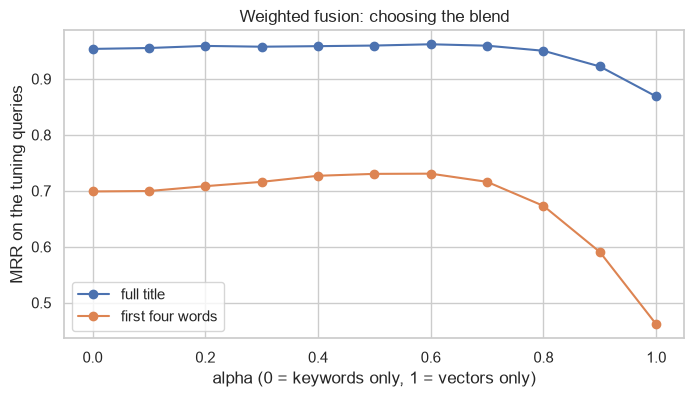

Best alpha on the tuning queries: {'full title': 0.6, 'first four words': 0.6}


In [5]:
alphas = np.round(np.arange(0, 1.01, 0.1), 1)
sweep = pd.DataFrame({
    kind: [summarise([rank_of(weighted_fusion(k, v, a), i) for (k, v), i in zip(scored[(kind, "tune")], tune_ids)])["MRR"]
           for a in alphas]
    for kind in ["full title", "first four words"]}, index=alphas)
best_alpha = sweep.idxmax().to_dict()

ax = sweep.plot(marker="o", figsize=(8, 4))
ax.set_xlabel("alpha (0 = keywords only, 1 = vectors only)")
ax.set_ylabel("MRR on the tuning queries")
ax.set_title("Weighted fusion: choosing the blend")
plt.show()
print("Best alpha on the tuning queries:", best_alpha)

In [6]:
def compare(kind):
    rows = {}
    methods = {
        "Keyword (BM25)": lambda k, v: k,
        "Vector": lambda k, v: v,
        "Hybrid: RRF": reciprocal_rank_fusion,
        f"Hybrid: weighted (alpha={best_alpha[kind]})": lambda k, v: weighted_fusion(k, v, best_alpha[kind]),
    }
    for name, combine in methods.items():
        ranks = [rank_of(combine(k, v), i) for (k, v), i in zip(scored[(kind, "test")], test_ids)]
        rows[name] = summarise(ranks)
    return pd.DataFrame(rows).T


results = {kind: compare(kind) for kind in ["full title", "first four words"]}
for kind, table in results.items():
    print(f"Query: {kind} (500 test queries)")
    display(table.round(3))

Query: full title (500 test queries)


,recall@1,recall@5,recall@10,MRR
Keyword (BM25),0.932,0.972,0.978,0.951
Vector,0.842,0.940,0.960,0.889
Hybrid: RRF,0.920,0.978,0.982,0.947
Hybrid: weighted (alpha=0.6),0.958,0.982,0.990,0.970


Query: first four words (500 test queries)


,recall@1,recall@5,recall@10,MRR
Keyword (BM25),0.658,0.768,0.816,0.710
Vector,0.374,0.556,0.632,0.462
Hybrid: RRF,0.554,0.714,0.800,0.633
Hybrid: weighted (alpha=0.6),0.672,0.780,0.832,0.727


When do the two retrievers disagree? Counting, for the short queries, how often each one finds the paper in its top ten:

In [7]:
k_hit = np.array([rank_of(k, i) <= 10 for (k, v), i in zip(scored[("first four words", "test")], test_ids)])
v_hit = np.array([rank_of(v, i) <= 10 for (k, v), i in zip(scored[("first four words", "test")], test_ids)])
pd.crosstab(pd.Series(k_hit, name="keyword finds it"), pd.Series(v_hit, name="vector finds it"))

vector finds it,False,True
keyword finds it,,
False,70,22
True,114,294


### Does a reranker help?

A common next step is a second stage: take the hybrid's top candidates and rescore each one with a **cross-encoder**, a model that reads the query and the abstract together instead of comparing two separately computed vectors. It is more precise and much slower, so it only sees the top 20 here. The model is `ms-marco-MiniLM-L-6-v2`, trained on web search queries and passages.

In [8]:
from hybridsearch.rerank import CrossEncoderReranker

reranker = CrossEncoderReranker(papers["abstract"].tolist(), depth=20)
alpha = best_alpha["full title"]


def reranked(kind, make_query):
    ranks, seconds = [], 0.0
    for (k, v), i in zip(scored[(kind, "test")], test_ids):
        start = time.perf_counter()
        scores = reranker.rerank(make_query(papers.loc[i, "title"]), weighted_fusion(k, v, best_alpha[kind]))
        seconds += time.perf_counter() - start
        ranks.append(rank_of(scores, i))
    return summarise(ranks), 1000 * seconds / len(test_ids)


rerank_rows, rerank_ms = {}, {}
for kind, make_query in [("full title", lambda t: t), ("first four words", short)]:
    hybrid_name = f"Hybrid: weighted (alpha={best_alpha[kind]})"
    summary, ms = reranked(kind, make_query)
    rerank_rows[kind] = pd.DataFrame({"Hybrid": results[kind].loc[hybrid_name], "Hybrid + reranker": summary}).T
    rerank_ms[kind] = ms
    print(f"Query: {kind}, reranking the top 20 takes {ms:.0f} ms per query")
    display(rerank_rows[kind].round(3))

Query: full title, reranking the top 20 takes 58 ms per query


,recall@1,recall@5,recall@10,MRR
Hybrid,0.958,0.982,0.99,0.97
Hybrid + reranker,0.958,0.986,0.99,0.97


Query: first four words, reranking the top 20 takes 57 ms per query


,recall@1,recall@5,recall@10,MRR
Hybrid,0.672,0.780,0.832,0.727
Hybrid + reranker,0.726,0.826,0.852,0.773


On short queries the reranker puts the right paper first noticeably more often. On full titles there is nothing left to gain: the hybrid already ranks the right paper first 96% of the time. Searching itself takes well under a millisecond; reranking costs around a thousand times more, so it belongs only where queries are short or vague.

Is it also better at topical search?

In [9]:
topical_rerank = []
for (k, v), i in zip(scored[("full title", "test")], test_ids):
    scores = reranker.rerank(papers.loc[i, "title"], weighted_fusion(k, v, alpha))
    topical_rerank.append(category_precision(scores, categories, categories[i], k=10, exclude=i))
print(f"Share of the top ten in the query paper's category, hybrid + reranker: {np.mean(topical_rerank):.3f}")

Share of the top ten in the query paper's category, hybrid + reranker: 0.693


Slightly *worse* than the hybrid without reranking (0.701 in the next section). The cross-encoder was trained to judge whether a passage answers a query, not whether two papers are on the same subject, so it promotes abstracts that share the title's exact phrasing over ones in the same field. A reranker is only as good as the match between its training task and yours.

## 4. Topical search

Known-item search rewards exact wording. A different need is "show me papers on this subject". As a proxy, each query paper's title is searched and the share of the top ten results in the same arXiv category is measured, leaving out the paper itself. The categories overlap in practice (a paper on language models for code could sit in three of them), so this measures broad topical agreement and nothing finer.

In [10]:
topical = {}
methods = {"Keyword (BM25)": lambda k, v: k, "Vector": lambda k, v: v, "Hybrid: RRF": reciprocal_rank_fusion,
           "Hybrid: weighted": lambda k, v: weighted_fusion(k, v, best_alpha["full title"])}
for name, combine in methods.items():
    precisions = [category_precision(combine(k, v), categories, categories[i], k=10, exclude=i)
                  for (k, v), i in zip(scored[("full title", "test")], test_ids)]
    by_category = pd.Series(precisions).groupby(categories[test_ids]).mean()
    topical[name] = {"all": float(np.mean(precisions)), **by_category.to_dict()}
pd.DataFrame(topical).T.round(3)

,all,cs.CL,cs.CV,cs.DB,cs.LG,cs.SE
Keyword (BM25),0.585,0.480,0.668,0.667,0.468,0.644
Vector,0.706,0.621,0.761,0.814,0.584,0.746
Hybrid: RRF,0.695,0.596,0.752,0.803,0.567,0.756
Hybrid: weighted,0.701,0.616,0.754,0.810,0.576,0.745


## 5. Metadata filters: speed and correctness

Real searches come with conditions: only this category, only papers since a given date. The same filtered vector search is run on three engines:

- **NumPy:** exact search. Apply the filter as a mask, score everything left.
- **ChromaDB:** an approximate HNSW index with metadata filters.
- **Qdrant in local mode:** the in-process version of Qdrant, with payload filters.

Each is timed on 200 queries with no filter, a category filter (keeps 20% of papers), a date filter (keeps roughly half), and both. "Agreement with exact" is the share of the true top ten that the engine returns.

In [11]:
dates = papers["date"].to_numpy()
date_cut = int(np.median(dates))
print(f"Date filter: published on or after {date_cut} keeps {(dates >= date_cut).mean():.0%} of papers")

exact = NumpyBackend(abstract_vectors, categories, dates)
engines = [exact]
for backend in (ChromaBackend, QdrantBackend):
    start = time.perf_counter()
    engines.append(backend(abstract_vectors, categories.tolist(), dates.tolist()))
    print(f"{backend.name}: loaded in {time.perf_counter() - start:.1f} s")

bench_ids = rng.choice(len(papers), size=200, replace=False)
bench_vectors = vector.embed(papers.loc[bench_ids, "title"].tolist())
filters = {"no filter": {}, "category": {"category": "cs.DB"}, "date": {"date_from": date_cut},
           "category + date": {"category": "cs.DB", "date_from": date_cut}}

rows = []
for engine in engines:
    for label, kwargs in filters.items():
        rows.append({"engine": engine.name, "filter": label, **benchmark(engine, bench_vectors, exact, **kwargs)})
bench = pd.DataFrame(rows)

display(bench.pivot(index="filter", columns="engine", values="median ms").loc[list(filters)].round(2))
bench.pivot(index="filter", columns="engine", values="agreement with exact").loc[list(filters)].round(3)

Date filter: published on or after 20261001 keeps 51% of papers


ChromaDB (HNSW): loaded in 1.0 s


Qdrant (local mode): loaded in 0.7 s


engine,ChromaDB (HNSW),NumPy (exact),Qdrant (local mode)
filter,,,
no filter,0.47,0.05,1.24
category,2.30,0.06,14.94
date,3.26,0.04,14.84
category + date,2.92,0.05,16.79


engine,ChromaDB (HNSW),NumPy (exact),Qdrant (local mode)
filter,,,
no filter,0.997,1.0,1.0
category,0.999,1.0,1.0
date,0.998,1.0,1.0
category + date,1.000,1.0,1.0


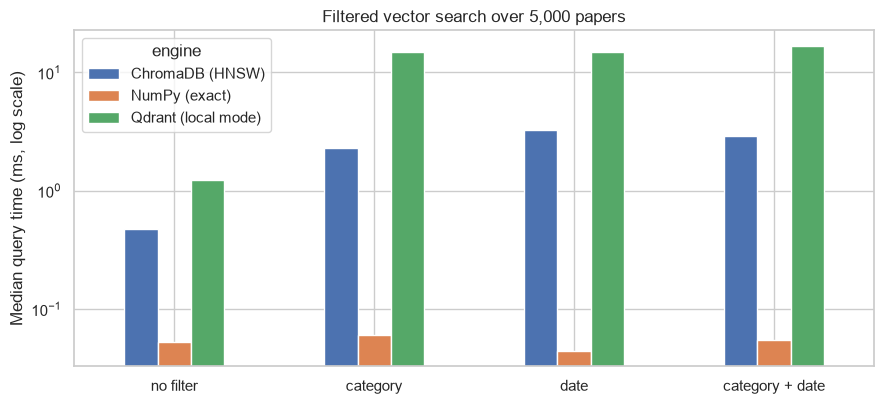

engine,ChromaDB (HNSW),NumPy (exact),Qdrant (local mode)
slowdown relative to no filter,,,
no filter,1.00,1.00,1.00
category,4.88,1.14,12.04
date,6.92,0.83,11.96
category + date,6.20,1.03,13.53


In [12]:
pivot = bench.pivot(index="filter", columns="engine", values="median ms").loc[list(filters)]
ax = pivot.plot.bar(figsize=(9, 4.2), rot=0, logy=True)
ax.set_ylabel("Median query time (ms, log scale)")
ax.set_xlabel("")
ax.set_title("Filtered vector search over 5,000 papers")
plt.tight_layout()
plt.show()

(pivot / pivot.loc["no filter"]).round(2).rename_axis("slowdown relative to no filter")

## Findings

**Which retriever is best depends on the question being asked.**

- **Looking for a specific paper, keywords win.** With the full title as the query, BM25 puts the right abstract first 93% of the time and vector search 84%. With only the first four words of the title the gap is much wider: 66% against 37%. Titles and abstracts share distinctive terms (method names, dataset names, acronyms), and exact matching on rare words is what BM25 is built for.
- **Looking for papers on a subject, vectors win.** 71% of the top ten vector results are in the query paper's category, against 59% for BM25.
- **Hybrid is not automatically better.** Reciprocal rank fusion was *worse* than BM25 alone on known-item search (92% against 93% on full titles, 55% against 66% on short queries), because it gives the weaker retriever an equal vote. Weighted fusion with a tuned blend was the best on known-item search (96% and 67%), and close to vector search on topical search. The gain over the better single retriever is a point or two, and it depended on tuning the weight on held-out queries.
- **A reranker helps where the first stage is weakest, at a price.** Rescoring the hybrid's top 20 with a cross-encoder raised the share of short queries answered first from 67% to 73%, and did nothing for full titles, which were already at 96%. It made topical search slightly worse (69% against 70%), because the model was trained to match questions to answers, not papers to subjects. It costs about 57 ms per query against well under a millisecond for search itself.
- **The retrievers fail on different queries.** On short queries, keyword search alone found 114 papers that vector search missed, and vector search found 22 that keywords missed. That overlap pattern is the real argument for combining them.

**Filters cost time on indexed engines, and at this size an index is not needed.**

- Exact search with NumPy answers in well under a tenth of a millisecond with or without a filter. With 5,000 vectors there is nothing for an index to speed up.
- ChromaDB's filtered queries take several times longer than its unfiltered ones, and Qdrant's local mode around twelve times longer. Both return essentially the same results as exact search.
- These are small-scale, in-process timings on a laptop. Qdrant's local mode is a convenience for development and says little about a Qdrant server, and the picture changes at millions of vectors, where exact search stops being an option. The honest conclusion is narrower: do not reach for a vector database, or for hybrid search, before measuring whether the simple version already does the job.

Limits: one embedding model, one corpus of recent computer science abstracts, and queries derived from titles. Titles are written by the authors of the abstracts, which favours keyword matching more than real user queries would.